## Funding carry in two wallets

Long Bitcoin on spot and short its perpetual in one account at Bybit, the same size each,
so the price moves of the two legs offset and the short's funding is what is left. The
account keeps two wallets: the spot wallet holds the coin, the margin wallet backs the
short, and cash crosses between them only when moved. Hourly bars of 2024 and 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### Spot and perpetual on one clock

Bybit's spot pair and its perpetual, each fetched once into `bars/`, joined into one Data
whose names say each one's market.

In [2]:
SPOT = pathlib.Path("../bars/bybit-spot-btcusdt-1h-2024-2025")
PERP = pathlib.Path("../bars/bybit-linear-btcusdt-ethusdt-1h-2024-2025")

if SPOT.exists():
    spot = probatum.Data.load(path=SPOT)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        spot = probatum.Data.from_router(router, exchange="bybit", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    spot.save(path=SPOT)

if PERP.exists():
    perp = probatum.Data.load(path=PERP)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        perp = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=PERP)

both = spot.join(perp["BTCUSDT"])

print(both, both.names)

Data(2 instruments, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00) ('spot:BTCUSDT', 'linear:BTCUSDT')


### The account and its wallets

`bybit` is the preset that lists the venue's spot pairs and linear perpetuals in one
account. Its balance opens each wallet by name.

In [3]:
venue = probatum.venues.bybit.replace(balance={"spot": 5_000.0, "margin": 5_000.0})

venue

probatum.venues.bybit.replace(balance={'spot': 5000.0, 'margin': 5000.0})

### The strategy

Once a day it brings each leg to 45% of the account. `transfer=True` moves across from the
margin wallet what the spot leg's purchase lacks, and the spot wallet's cash beyond what the
purchase needs, which a sale of the coin leaves there as the price rises, goes back to the
margin wallet, where the short needs it.

In [4]:
class Carry(probatum.Strategy):
    def __init__(self, weight=0.45):
        self.weight = weight

    def next(self, bar, account):
        if bar.time.hour != 0:
            return

        needed = max(0.0, self.weight - account["spot:BTCUSDT"].weight) * account.equity
        spare  = account.spot.cash - needed * 1.01
        if spare > 1.0:
            account.transfer(amount=spare, to="margin")

        account.target(weights={"spot:BTCUSDT": self.weight,
                                "linear:BTCUSDT": -self.weight},
                       tolerance=0.02, transfer=True)


result = probatum.backtest(Carry(), data=both, venue=venue)

result

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,6.91,89.72,4.29,9.41,0.95,"studentized stationary block bootstrap, blocks of 165.3 bars",
cagr_pct,3.39,37.68,2.12,4.59,0.95,"studentized stationary block bootstrap, blocks of 165.3 bars",
volatility_pct,0.74,50.81,0.68,0.82,0.95,"studentized stationary block bootstrap, blocks of 165.3 bars",
sharpe,4.50,0.88,3.11,5.89,0.95,"delta method, Newey-West lag 32, floored at lag zero",
max_drawdown_pct,0.42,36.85,0.22,0.57,0.95,"middle of resampled histories, stationary block bootstrap, blocks of 165.3 bars",
exposure_pct,100.00,,,,,,
num_trades,0,,,,,,
win_rate,,,,,,,1
profit_factor,,,,,,,1
costs,-744,,,,,,


### Where the money went

The two legs' pnl, which their prices move against each other, and the costs, funding a
negative sum where the short received it.

In [5]:
print(f"spot leg      {result['spot:BTCUSDT'].pnl[-1]:>12,.2f} USDT")
print(f"perpetual leg {result['linear:BTCUSDT'].pnl[-1]:>12,.2f} USDT")

pandas.Series(result.costs).round(decimals=2)

spot leg          4,272.19 USDT
perpetual leg    -3,580.90 USDT


fees            53.65
funding       -804.61
spread           0.00
slippage         6.57
impact           0.06
liquidation      0.00
dust             0.00
dtype: float64

### The two wallets

The ledger's cash in each wallet at every close, the coin's value in the spot wallet beside
it, and the funding received to date.

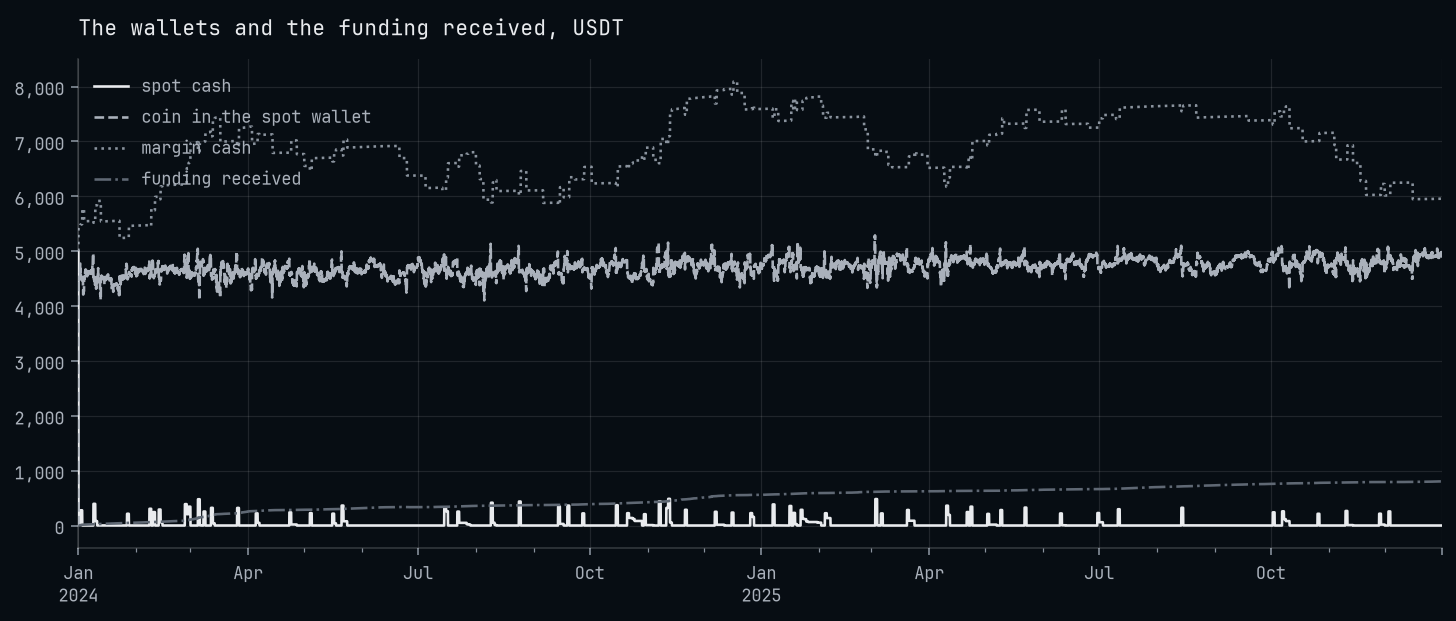

In [6]:
ledger   = result.ledger.to_pandas().set_index(keys="time")
holdings = result.holdings.to_pandas()
coin     = holdings[holdings["instrument"] == "spot:BTCUSDT"].set_index(keys="time")

wallets = pandas.DataFrame({"spot cash": ledger["spot_cash"],
                            "coin in the spot wallet": coin["notional"],
                            "margin cash": ledger["margin_cash"],
                            "funding received": -ledger["funding"].cumsum()})

axes = wallets.plot(title="The wallets and the funding received, USDT", xlabel="")
axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
matplotlib.pyplot.show()